# Customer Shopping Behavior Analysis

**Goal:** understand what drives revenue for a retail brand - who buys, what they buy, when, and whether
discounts and subscriptions actually pay off - and turn that into concrete recommendations.

**Notebook outline**
1. Data loading & quality checks
2. Exploratory data analysis (visual)
3. Statistical hypothesis testing - *are the differences we see real or just noise?*
4. Customer value segmentation
5. Key insights & recommendations

> Run `python scripts/step1_clean_data.py` first - it creates the cleaned CSV and the SQLite database used here.

In [1]:
from pathlib import Path
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
IMG = ROOT / "charts"
IMG.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMG / f"{name}.png", bbox_inches="tight")

df = pd.read_csv(ROOT / "data/processed/customer_shopping_data_clean.csv")
df["age_group"] = pd.Categorical(df["age_group"], ["18-30", "31-45", "46-60", "60+"], ordered=True)
print(df.shape)
df.head()

(3900, 21)


,customer_id,age,gender,item_purchased,category,purchase_amount,location,size,color,season,...,subscription_status,shipping_type,discount_applied,previous_purchases,payment_method,frequency_of_purchases,age_group,purchase_frequency_days,est_purchases_per_year,customer_segment
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,...,Yes,Express,Yes,14,Venmo,Fortnightly,46-60,14,26.1,Loyal
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,...,Yes,Express,Yes,2,Cash,Fortnightly,18-30,14,26.1,Returning
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,...,Yes,Free Shipping,Yes,23,Credit Card,Weekly,46-60,7,52.1,Loyal
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,...,Yes,Next Day Air,Yes,49,PayPal,Weekly,18-30,7,52.1,Loyal
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,...,Yes,Free Shipping,Yes,31,PayPal,Annually,31-45,365,1.0,Loyal


## 1. Data quality checks

In [2]:
raw = pd.read_csv(ROOT / "data/raw/customer_shopping_data_raw.csv", encoding="utf-8-sig")
print("Missing values in raw data:")
print(raw.isna().sum()[raw.isna().sum() > 0])
print("\nDuplicate customer IDs:", df["customer_id"].duplicated().sum())
print("Missing values after cleaning:", df.isna().sum().sum())
df.describe().round(2)

Missing values in raw data:
Review Rating    37
dtype: int64

Duplicate customer IDs: 0
Missing values after cleaning: 0


,customer_id,age,purchase_amount,review_rating,previous_purchases,purchase_frequency_days,est_purchases_per_year
count,3900.00,3900.00,3900.00,3900.00,3900.00,3900.00,3900.00
mean,1950.50,44.07,59.76,3.75,25.35,89.13,17.57
std,1125.98,15.21,23.69,0.71,14.45,119.04,16.82
min,1.00,18.00,20.00,2.50,1.00,7.00,1.00
25%,975.75,31.00,39.00,3.10,13.00,14.00,4.10
50%,1950.50,44.00,60.00,3.80,25.00,30.00,12.20
75%,2925.25,57.00,81.00,4.40,38.00,90.00,26.10
max,3900.00,70.00,100.00,5.00,50.00,365.00,52.10


In [3]:
# Sanity check: how do subscriptions and discount usage split by gender?
from IPython.display import display
display(pd.crosstab(df["gender"], df["subscription_status"], margins=True).rename_axis(columns="subscribed"))
display(pd.crosstab(df["gender"], df["discount_applied"], margins=True).rename_axis(columns="discount used"))

subscribed,No,Yes,All
gender,,,
Female,1248,0,1248
Male,1599,1053,2652
All,2847,1053,3900


discount used,No,Yes,All
gender,,,
Female,1248,0,1248
Male,975,1677,2652
All,2223,1677,3900


## 2. Exploratory data analysis

In [4]:
total_rev = df["purchase_amount"].sum()
kpis = {
    "Customers": f"{len(df):,}",
    "Total revenue": f"${total_rev:,.0f}",
    "Avg order value": f"${df['purchase_amount'].mean():.2f}",
    "Avg review rating": f"{df['review_rating'].mean():.2f} / 5",
    "Subscription rate": f"{(df['subscription_status'] == 'Yes').mean():.1%}",
    "Discount usage": f"{(df['discount_applied'] == 'Yes').mean():.1%}",
}
pd.Series(kpis, name="value").to_frame()

,value
Customers,"3,900"
Total revenue,"$233,081"
Avg order value,$59.76
Avg review rating,3.75 / 5
Subscription rate,27.0%
Discount usage,43.0%


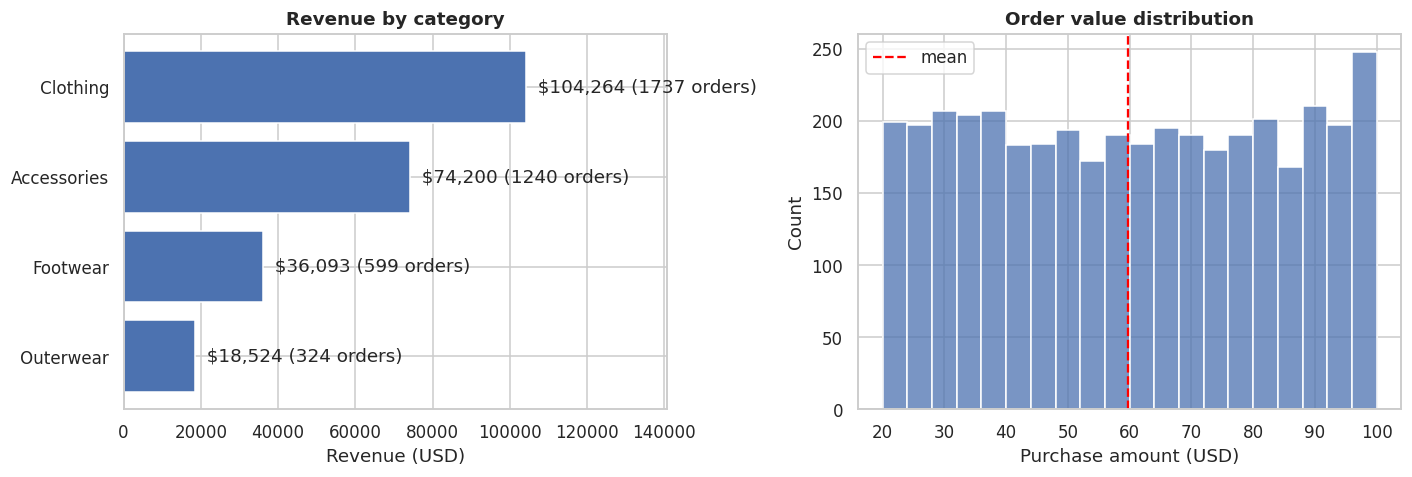

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

cat = df.groupby("category")["purchase_amount"].agg(["sum", "count"]).sort_values("sum")
axes[0].barh(cat.index, cat["sum"], color=sns.color_palette()[0])
for i, (s, c) in enumerate(zip(cat["sum"], cat["count"])):
    axes[0].text(s, i, f"  ${s:,.0f} ({c} orders)", va="center")
axes[0].set(title="Revenue by category", xlabel="Revenue (USD)")
axes[0].set_xlim(0, cat["sum"].max() * 1.35)

sns.histplot(df["purchase_amount"], bins=20, ax=axes[1])
axes[1].axvline(df["purchase_amount"].mean(), color="red", ls="--", label="mean")
axes[1].set(title="Order value distribution", xlabel="Purchase amount (USD)")
axes[1].legend()
save(fig, "revenue_by_category_and_order_value")

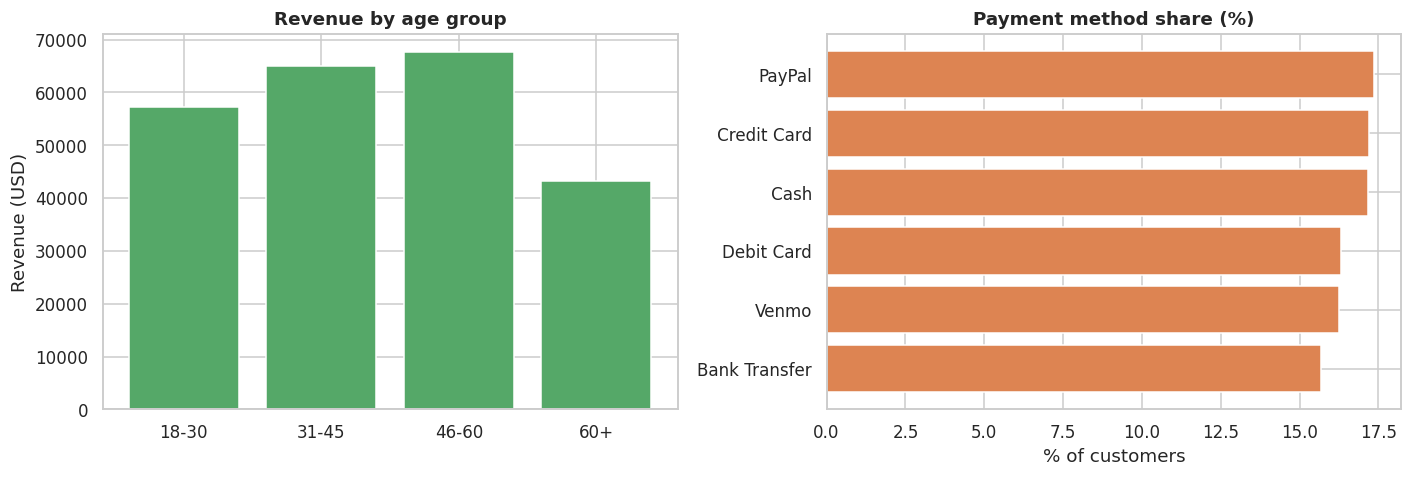

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

age = df.groupby("age_group", observed=True)["purchase_amount"].sum()
axes[0].bar(age.index.astype(str), age.values, color=sns.color_palette()[2])
axes[0].set(title="Revenue by age group", ylabel="Revenue (USD)")

pay = df["payment_method"].value_counts(normalize=True).sort_values() * 100
axes[1].barh(pay.index, pay.values, color=sns.color_palette()[1])
axes[1].set(title="Payment method share (%)", xlabel="% of customers")
save(fig, "revenue_by_age_and_payment_methods")

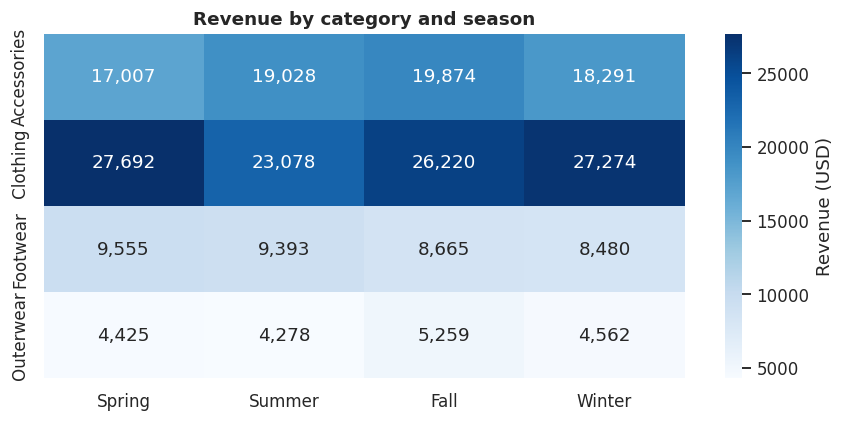

In [7]:
pivot = df.pivot_table(index="category", columns="season", values="purchase_amount",
                       aggfunc="sum")[["Spring", "Summer", "Fall", "Winter"]]
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(pivot, annot=True, fmt=",.0f", cmap="Blues", ax=ax, cbar_kws={"label": "Revenue (USD)"})
ax.set(title="Revenue by category and season", xlabel="", ylabel="")
save(fig, "revenue_heatmap_season_vs_category")

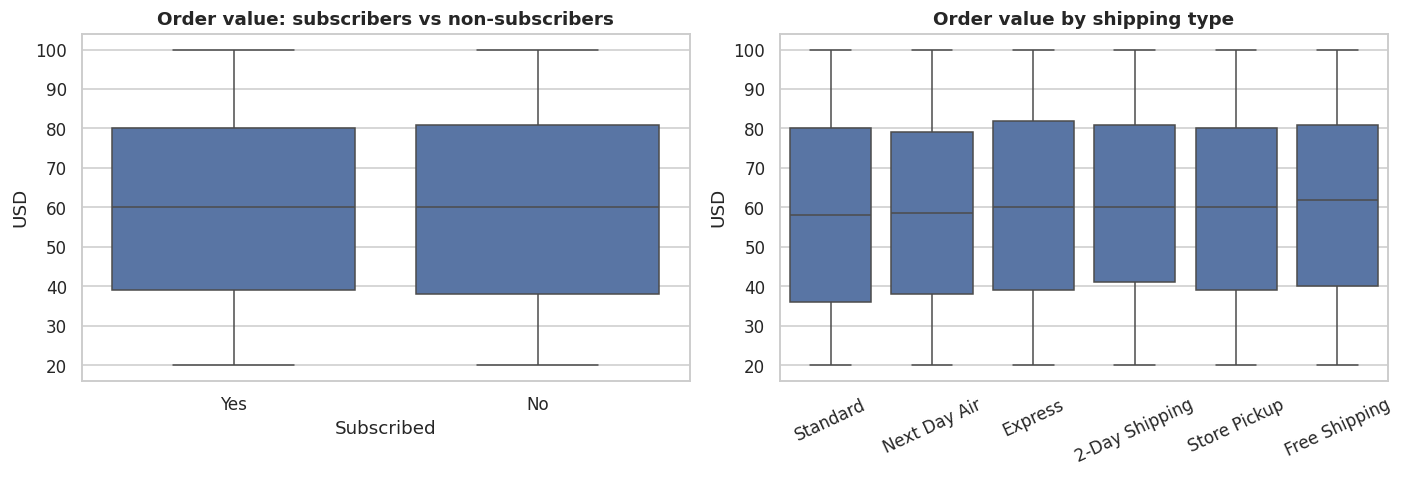

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="subscription_status", y="purchase_amount", ax=axes[0])
axes[0].set(title="Order value: subscribers vs non-subscribers", xlabel="Subscribed", ylabel="USD")
sns.boxplot(data=df, x="shipping_type", y="purchase_amount", ax=axes[1],
            order=df.groupby("shipping_type")["purchase_amount"].median().sort_values().index)
axes[1].set(title="Order value by shipping type", xlabel="", ylabel="USD")
axes[1].tick_params(axis="x", rotation=25)
save(fig, "order_value_by_subscription_and_shipping")

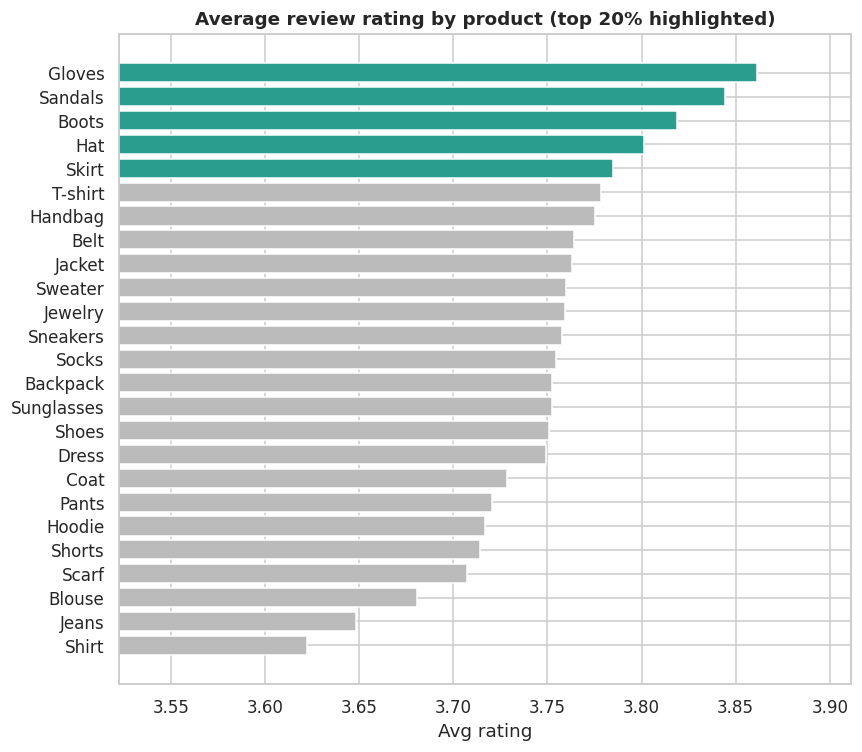

In [9]:
top_rated = df.groupby("item_purchased")["review_rating"].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
colors = ["#2a9d8f" if v >= top_rated.quantile(0.8) else "#bbbbbb" for v in top_rated]
ax.barh(top_rated.index, top_rated.values, color=colors)
ax.set(title="Average review rating by product (top 20% highlighted)", xlabel="Avg rating",
       xlim=(top_rated.min() - 0.1, top_rated.max() + 0.05))
save(fig, "product_review_ratings")

## 3. Statistical hypothesis testing

Charts show differences, but are they **statistically significant** or just random variation?
Significance level: **α = 0.05**.

| # | Question | Test |
|---|----------|------|
| H1 | Do subscribers spend more per order? | Welch's t-test |
| H2 | Do discounted orders have a different order value? | Welch's t-test |
| H3 | Does order value differ across seasons? | One-way ANOVA |
| H4 | Is product category preference related to gender? | Chi-square test of independence |
| H5 | Are loyal customers (many previous purchases) more likely to subscribe? | Chi-square test |

In [10]:
ALPHA = 0.05
results = []

def record(name, test, stat, p, effect=""):
    results.append({"hypothesis": name, "test": test, "statistic": round(stat, 3),
                    "p_value": round(p, 4), "significant": p < ALPHA, "effect": effect})

# H1 - subscribers vs non-subscribers
a = df.loc[df.subscription_status == "Yes", "purchase_amount"]
b = df.loc[df.subscription_status == "No", "purchase_amount"]
t, p = stats.ttest_ind(a, b, equal_var=False)
record("H1 subscribers spend more", "Welch t-test", t, p, f"mean diff = ${a.mean() - b.mean():.2f}")

# H2 - discount vs no discount
a = df.loc[df.discount_applied == "Yes", "purchase_amount"]
b = df.loc[df.discount_applied == "No", "purchase_amount"]
t, p = stats.ttest_ind(a, b, equal_var=False)
record("H2 discount changes order value", "Welch t-test", t, p, f"mean diff = ${a.mean() - b.mean():.2f}")

# H3 - season
groups = [g["purchase_amount"].values for _, g in df.groupby("season")]
f, p = stats.f_oneway(*groups)
record("H3 order value differs by season", "ANOVA", f, p)

# H4 - gender x category
ct = pd.crosstab(df["gender"], df["category"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
record("H4 category depends on gender", "Chi-square", chi2, p, f"Cramer's V = {cramers_v:.3f}")

# H5 - customer segment x subscription
ct = pd.crosstab(df["customer_segment"], df["subscription_status"])
chi2, p, dof, _ = stats.chi2_contingency(ct)
record("H5 loyal customers subscribe more", "Chi-square", chi2, p)

pd.DataFrame(results)

,hypothesis,test,statistic,p_value,significant,effect
0,H1 subscribers spend more,Welch t-test,-0.440,0.6603,False,mean diff = $-0.37
1,H2 discount changes order value,Welch t-test,-1.112,0.2661,False,mean diff = $-0.85
2,H3 order value differs by season,ANOVA,3.746,0.0106,True,
3,H4 category depends on gender,Chi-square,0.598,0.8968,False,Cramer's V = 0.012
4,H5 loyal customers subscribe more,Chi-square,7.578,0.0226,True,


## 4. Customer value segmentation

Each customer gets a 1-4 quartile score on three dimensions - **spend** (order value), **loyalty**
(previous purchases) and **frequency** (estimated purchases per year). The total score (3-12) places
them in a High / Mid / Low value tier. The same logic is implemented in SQL (Q14).

In [11]:
seg = df.copy()
for col, score in [("purchase_amount", "spend_score"),
                   ("previous_purchases", "loyalty_score"),
                   ("est_purchases_per_year", "frequency_score")]:
    seg[score] = pd.qcut(seg[col].rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)

seg["value_score"] = seg[["spend_score", "loyalty_score", "frequency_score"]].sum(axis=1)
seg["value_tier"] = pd.cut(seg["value_score"], bins=[2, 6, 9, 12],
                           labels=["Low value", "Mid value", "High value"])
seg["est_annual_revenue"] = seg["purchase_amount"] * seg["est_purchases_per_year"]

tier_summary = seg.groupby("value_tier", observed=True).agg(
    customers=("customer_id", "count"),
    avg_order_value=("purchase_amount", "mean"),
    avg_previous_purchases=("previous_purchases", "mean"),
    subscription_rate=("subscription_status", lambda s: (s == "Yes").mean()),
    est_annual_revenue=("est_annual_revenue", "sum"),
).sort_index(ascending=False)
tier_summary["share_of_customers"] = tier_summary["customers"] / tier_summary["customers"].sum()
tier_summary["share_of_annual_revenue"] = tier_summary["est_annual_revenue"] / tier_summary["est_annual_revenue"].sum()
tier_summary.round(2)

,customers,avg_order_value,avg_previous_purchases,subscription_rate,est_annual_revenue,share_of_customers,share_of_annual_revenue
value_tier,,,,,,,
High value,596,80.44,38.15,0.20,1457877.0,0.15,0.36
Mid value,2094,62.46,27.15,0.26,2250799.0,0.54,0.55
Low value,1210,44.91,15.93,0.32,366300.2,0.31,0.09


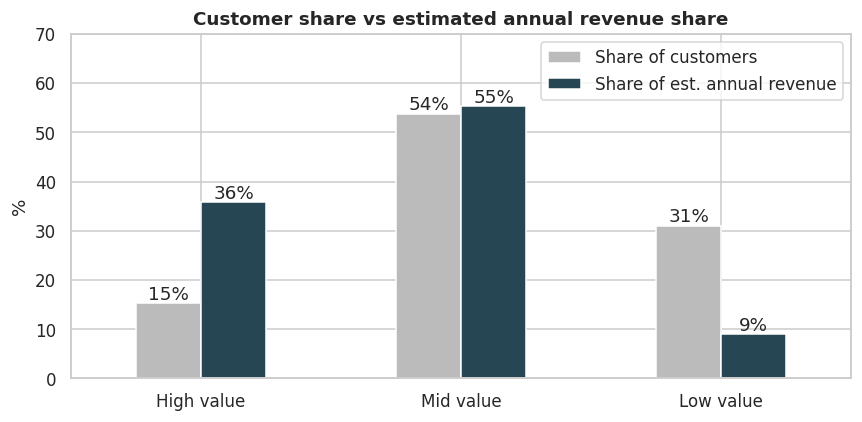

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
shares = tier_summary[["share_of_customers", "share_of_annual_revenue"]] * 100
shares.plot.bar(ax=ax, color=["#bbbbbb", "#264653"], rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f%%")
ax.set(title="Customer share vs estimated annual revenue share", ylabel="%", xlabel="", ylim=(0, 70))
ax.legend(["Share of customers", "Share of est. annual revenue"])
save(fig, "customer_value_tiers")

In [13]:
# Who are the high-value customers?
high = seg[seg["value_tier"] == "High value"]
profile = pd.DataFrame({
    "High value": [high["age"].mean(), (high["subscription_status"] == "Yes").mean(),
                   (high["discount_applied"] == "Yes").mean(), high["review_rating"].mean()],
    "All customers": [seg["age"].mean(), (seg["subscription_status"] == "Yes").mean(),
                      (seg["discount_applied"] == "Yes").mean(), seg["review_rating"].mean()],
}, index=["avg age", "subscription rate", "discount usage", "avg rating"]).round(3)
print("Top categories among high-value customers:")
print(high["category"].value_counts(normalize=True).round(3))
profile

Top categories among high-value customers:
category
Clothing       0.446
Accessories    0.305
Footwear       0.158
Outerwear      0.091
Name: proportion, dtype: float64


,High value,All customers
avg age,44.201,44.068
subscription rate,0.200,0.270
discount usage,0.317,0.430
avg rating,3.787,3.750


In [14]:
seg[["customer_id", "spend_score", "loyalty_score", "frequency_score", "value_score", "value_tier"]] \
    .to_csv(ROOT / "results/customer_value_tiers.csv", index=False)
print("Saved results/customer_value_tiers.csv")

Saved results/customer_value_tiers.csv


## 5. Key insights & recommendations

**What the data says**

1. **Revenue is concentrated in Clothing (~45%) and Accessories (~32%)** in every season. Outerwear stays
   below 9% of revenue *even in winter*, which points to a weak or under-promoted outerwear range.
2. **Subscribers do not spend more per order** ($59.49 vs $59.87, p = 0.66). The subscription programme
   is not lifting basket size.
3. **Discounts do not increase order value** (p = 0.27). Discount users spend about the same, and in
   Outerwear and Accessories they spend *less*. With 43% of orders discounted, this is margin given away.
4. **Season matters, a little:** Fall has the highest average order value ($61.56) and Summer the lowest
   ($58.41). The ANOVA is significant (p = 0.011), but the effect is about $3 per order.
5. **Loyalty predicts subscription:** Loyal customers subscribe at 27.9% vs 18.1% for New customers
   (chi-square p = 0.023).
6. **Value tiers:** the High-value tier is about **15% of customers but about 36% of estimated annual revenue**.
   These customers use *fewer* discounts (32% vs 43%) and subscribe *less* (20% vs 27%) than average.
7. **Revenue is spread geographically:** the top 10 states make up only 23% of revenue, so there is no
   single market to over-index on.
8. **Data-quality flag:** every subscriber and every discount user in the dataset is male. A real business
   would need to check whether this is a tracking/collection issue before acting on gender-based findings.

**Recommendations**

* **Rework discounts:** move from blanket discounts to targeted ones (e.g. win-back offers for the Low-value tier),
  and A/B test removing discounts on Outerwear and Accessories, where they show no lift.
* **Redesign the subscription offer** around frequency and perks (free express shipping, early access)
  rather than price, and pitch it to High-value and Loyal customers first. They buy often but are under-subscribed.
* **Protect the High-value tier:** a VIP/loyalty programme for the top 15% protects about a third of revenue.
* **Plan inventory and campaigns around Fall/Winter** (highest order values) and invest in the Outerwear range.
* **Fix data collection** for subscription and discount tracking across genders.

> The SQL version of these value tiers (Q14) gives the same tier counts, which confirms the logic is consistent across Python and SQL.